<div style="background:linear-gradient(90deg,#134e5e,#71b280);padding:26px;border-radius:14px;color:white">
<h1 style="margin:6px 0 4px 0">McCulloch-Pitts Neuron (1943)</h1>
<p style="margin:0">The very first mathematical model of a neuron, and the starting point of the whole neural-network story.</p>
</div>

<br>

| 🪪 Quick card | |
|---|---|
| **Year** | 1943 |
| **Inventors** | Warren McCulloch (neurophysiologist) and Walter Pitts (logician) |
| **Family** | Neural models → ancestor of Perceptron and Deep Learning |
| **Learns from data?** | ❌ No. Its numbers are set by hand |
| **Inputs / Output** | Binary only: `0` or `1` |
| **Difficulty** | ⭐ Beginner |

### 🎯 What you will learn in this notebook
1. The story: why this model was invented
2. How a real neuron inspired it
3. The one-line formula behind it
4. Build it from scratch in Python
5. Use it to build logic gates (AND, OR, NOT, NOR, NAND)
6. See why it **cannot** do XOR alone, then fix it with a small network
7. Real examples: a majority vote, a burglar alarm, and a 1-bit adder

## 📖 Part 1: The story

In **1943**, two very different people met in Chicago:
- **Warren McCulloch**, a neurophysiologist who studied how the brain works.
- **Walter Pitts**, a young self-taught logician fascinated by mathematical logic.

They asked one question: **can the brain's activity be described with logic?**

Their paper, *"A Logical Calculus of the Ideas Immanent in Nervous Activity"*, answered with a simple model:
a neuron is a tiny switch that adds up the signals it receives and **fires (1)** only if the total is high enough. Otherwise it stays **silent (0)**.

They showed that networks of such switches can compute logical expressions, and they argued such networks could, in principle, do anything a Turing machine can. This idea started the line that leads to today's deep learning.

### 🗺️ Where this fits in the AI map
```
Neural models (1943: McCulloch-Pitts)  →  Perceptron (1958)  →  Backpropagation (1986)  →  Deep Learning (2012)  →  Transformers (2017)
```

## 🧠 Part 2: The idea in plain words

A real neuron:
- **Dendrites** receive signals from other neurons
- The **cell body** adds them up
- If the total passes a limit, the neuron sends a signal down its **axon** (all or nothing, like a light switch)

The McCulloch-Pitts neuron copies that:

| Real neuron | McCulloch-Pitts neuron |
|---|---|
| Signals arriving | Binary inputs `x1, x2, ...` (0 or 1) |
| Adding up signals | `sum = x1 + x2 + ...` |
| Firing limit | Threshold `θ` (theta) |
| Fires or not | Output `1` or `0` |
| Inhibiting (blocking) synapse | **Inhibitory input**: if it is `1`, the neuron is blocked completely (veto) |

### ➗ The formula
$$
y =
\begin{cases}
1 & \text{if } \sum x_i \ge \theta \ \text{ and no inhibitory input is } 1\\
0 & \text{otherwise}
\end{cases}
$$

That is the entire algorithm.

## 🟣 Step 1: Import the libraries
> 💡 `numpy` for numbers, `pandas` for tables, `matplotlib` for drawing, `itertools` to generate all input combinations.

In [1]:
# Import the libraries we need
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Ellipse, FancyArrowPatch

# A little styling so our charts look nice
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# Our colour palette (used across the notebook)
TEAL, GREEN, ORANGE, RED, PURPLE, GREY = "#134e5e", "#27ae60", "#f39c12", "#e74c3c", "#8e44ad", "#7f8c8d"

print("✅ Libraries ready!")

✅ Libraries ready!


## 🖼️ Step 2: Picture it: real neuron vs artificial neuron
> 💡 The left drawing is a simplified biological neuron. The right one is the McCulloch-Pitts neuron.
> Everything is drawn with code, so no image files are needed.

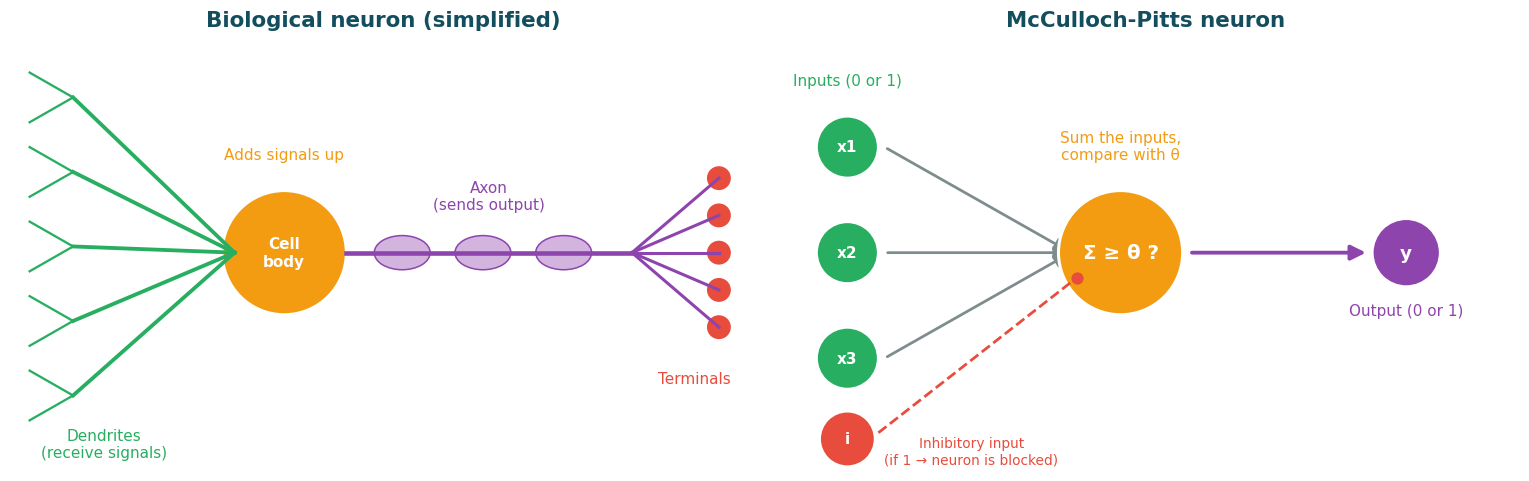

In [2]:
# Draw a biological neuron (left) next to the McCulloch-Pitts neuron (right)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.6))

# ---------- LEFT: biological neuron ----------
ax1.set_xlim(0, 12); ax1.set_ylim(0, 7); ax1.set_aspect("equal"); ax1.axis("off")
ax1.set_title("Biological neuron (simplified)", fontsize=14, color=TEAL, fontweight="bold")

# dendrites: lines going from the cell body to the left, with small branches
for y_start in [1.2, 2.4, 3.6, 4.8, 6.0]:
    ax1.plot([1.0, 3.6], [y_start, 3.5], color=GREEN, lw=2.5)
    ax1.plot([1.0, 0.3], [y_start, y_start + 0.4], color=GREEN, lw=1.5)
    ax1.plot([1.0, 0.3], [y_start, y_start - 0.4], color=GREEN, lw=1.5)

# cell body (soma)
ax1.add_patch(Circle((4.4, 3.5), 1.0, color=ORANGE, ec="white", lw=2))
ax1.text(4.4, 3.5, "Cell\nbody", ha="center", va="center", fontsize=10, color="white", fontweight="bold")

# axon with myelin sheath pieces
ax1.plot([5.4, 10.0], [3.5, 3.5], color=PURPLE, lw=3)
for x in [6.3, 7.6, 8.9]:
    ax1.add_patch(Ellipse((x, 3.5), 0.9, 0.55, color="#d2b4de", ec=PURPLE))

# axon terminals
for dy in [-1.2, -0.6, 0, 0.6, 1.2]:
    ax1.plot([10.0, 11.4], [3.5, 3.5 + dy], color=PURPLE, lw=2)
    ax1.add_patch(Circle((11.4, 3.5 + dy), 0.18, color=RED))

ax1.text(1.5, 0.2, "Dendrites\n(receive signals)", color=GREEN, ha="center", fontsize=10)
ax1.text(4.4, 5.0, "Adds signals up", color=ORANGE, ha="center", fontsize=10)
ax1.text(7.7, 4.2, "Axon\n(sends output)", color=PURPLE, ha="center", fontsize=10)
ax1.text(11.0, 1.4, "Terminals", color=RED, ha="center", fontsize=10)

# ---------- RIGHT: McCulloch-Pitts neuron ----------
ax2.set_xlim(0, 12); ax2.set_ylim(0, 7); ax2.set_aspect("equal"); ax2.axis("off")
ax2.set_title("McCulloch-Pitts neuron", fontsize=14, color=TEAL, fontweight="bold")

ys = [5.2, 3.5, 1.8]
for i, y in enumerate(ys, start=1):
    ax2.add_patch(Circle((1.2, y), 0.5, color=GREEN, ec="white", lw=2))
    ax2.text(1.2, y, f"x{i}", ha="center", va="center", color="white", fontweight="bold")
    ax2.add_patch(FancyArrowPatch((1.8, y), (4.8, 3.5), arrowstyle="-|>", mutation_scale=18, color=GREY, lw=1.8))

# inhibitory input (drawn with a round end, like a "blocker")
ax2.add_patch(Circle((1.2, 0.5), 0.45, color=RED, ec="white", lw=2))
ax2.text(1.2, 0.5, "i", ha="center", va="center", color="white", fontweight="bold")
ax2.plot([1.7, 4.9], [0.6, 3.1], color=RED, lw=1.8, ls="--")
ax2.plot([4.9], [3.1], marker="o", color=RED, ms=7)

# the neuron itself
ax2.add_patch(Circle((5.6, 3.5), 1.0, color=ORANGE, ec="white", lw=2))
ax2.text(5.6, 3.5, "Σ ≥ θ ?", ha="center", va="center", fontsize=13, color="white", fontweight="bold")

# output arrow
ax2.add_patch(FancyArrowPatch((6.7, 3.5), (9.6, 3.5), arrowstyle="-|>", mutation_scale=20, color=PURPLE, lw=2.5))
ax2.add_patch(Circle((10.2, 3.5), 0.55, color=PURPLE, ec="white", lw=2))
ax2.text(10.2, 3.5, "y", ha="center", va="center", color="white", fontweight="bold", fontsize=12)

ax2.text(1.2, 6.2, "Inputs (0 or 1)", color=GREEN, ha="center", fontsize=10)
ax2.text(3.2, 0.1, "Inhibitory input\n(if 1 → neuron is blocked)", color=RED, ha="center", fontsize=9)
ax2.text(5.6, 5.0, "Sum the inputs,\ncompare with θ", color=ORANGE, ha="center", fontsize=10)
ax2.text(10.2, 2.5, "Output (0 or 1)", color=PURPLE, ha="center", fontsize=10)

plt.tight_layout()
plt.show()

## 🤖 Step 3: Build the neuron from scratch
> 💡 We write a tiny Python class. It has two parts:
> - `threshold`: the firing limit θ
> - `__call__`: takes the inputs and returns `1` (fire) or `0` (silent)
>
> Rules: if **any** inhibitory input is `1`, the output is `0` no matter what. Otherwise, fire when the sum of the excitatory inputs is at least θ.

In [3]:
# The McCulloch-Pitts neuron as a Python class
class MPNeuron:
    '''A McCulloch-Pitts neuron: binary inputs, a threshold, and optional inhibitory inputs.'''

    def __init__(self, threshold):
        self.threshold = threshold              # θ: how much total signal we need to fire

    def __call__(self, excitatory, inhibitory=()):
        # Rule 1: any active inhibitory input blocks the neuron completely (veto)
        if any(inhibitory):
            return 0
        # Rule 2: otherwise fire only if the sum of excitatory inputs reaches the threshold
        return int(sum(excitatory) >= self.threshold)

print("✅ MPNeuron class created!")

✅ MPNeuron class created!


## 🔢 Step 4: A first example with real numbers
> 💡 A neuron with **3 inputs** and **θ = 2**. It fires when **at least 2 of the 3 inputs are on**. This is a **majority vote**.
> Imagine 3 friends voting on a movie: it wins if at least 2 say yes.

In [4]:
# Majority-vote neuron: 3 inputs, threshold = 2
majority = MPNeuron(threshold=2)

# Try every possible combination of 3 binary inputs (2 x 2 x 2 = 8 rows)
rows = []
for x1, x2, x3 in itertools.product([0, 1], repeat=3):
    rows.append({"x1": x1, "x2": x2, "x3": x3,
                 "sum": x1 + x2 + x3,
                 "output": majority([x1, x2, x3])})
majority_table = pd.DataFrame(rows)

# Colour the rows: green when the neuron fires, light red when it stays silent
def colour_rows(row):
    c = "background-color:#d5f5e3" if row["output"] == 1 else "background-color:#fadbd8"
    return [c] * len(row)

majority_table.style.apply(colour_rows, axis=1)

,x1,x2,x3,sum,output
0,0,0,0,0,0
1,0,0,1,1,0
2,0,1,0,1,0
3,0,1,1,2,1
4,1,0,0,1,0
5,1,0,1,2,1
6,1,1,0,2,1
7,1,1,1,3,1


## 📈 Step 5: The "step" behaviour
> 💡 The neuron's output is a **step function**: `0` until the sum reaches θ, then it jumps to `1`. There is nothing in between. This is the same "all or nothing" behaviour as a real neuron.

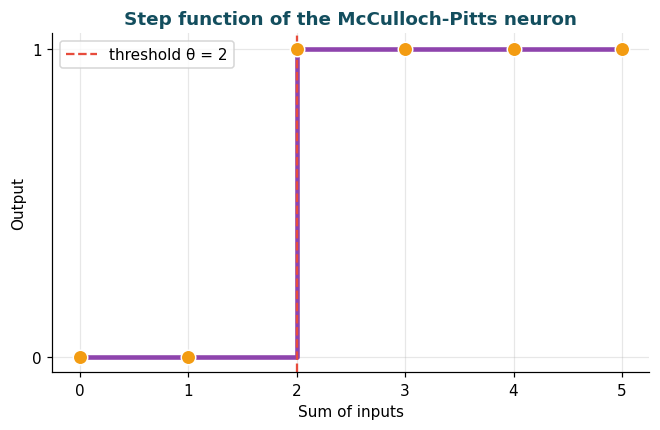

In [5]:
# Plot output vs. sum of inputs for θ = 2
sums = np.arange(0, 6)
outputs = [int(s >= 2) for s in sums]

plt.figure(figsize=(7, 4))
plt.step(sums, outputs, where="post", color=PURPLE, lw=3)
plt.scatter(sums, outputs, color=ORANGE, s=90, zorder=3, edgecolor="white")
plt.axvline(2, color=RED, ls="--", label="threshold θ = 2")
plt.title("Step function of the McCulloch-Pitts neuron", color=TEAL, fontweight="bold")
plt.xlabel("Sum of inputs")
plt.ylabel("Output")
plt.yticks([0, 1])
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 🔌 Step 6: Logic gates with one neuron
> 💡 Computers are built from logic gates. McCulloch and Pitts showed that these tiny neurons can act like gates:
>
> | Gate | How the neuron is set |
> |---|---|
> | **AND** | 2 inputs, θ = 2 (both must be on) |
> | **OR** | 2 inputs, θ = 1 (at least one on) |
> | **NOT** | a constant `1` input, plus the input as **inhibitory** |
> | **NOR** | a constant `1` input, plus **both** inputs as inhibitory |
> | **NAND** | NOT applied after AND (needs 2 neurons) |
>
> Why the constant `1` for NOT and NOR? Without any excitatory signal, a neuron with θ = 1 could never fire.

In [6]:
# Define each logic gate using MPNeuron
def AND(a, b):  return MPNeuron(2)([a, b])             # fires only if both are 1
def OR(a, b):   return MPNeuron(1)([a, b])             # fires if at least one is 1
def NOT(a):     return MPNeuron(1)([1], [a])           # constant 1, blocked when a = 1
def NOR(a, b):  return MPNeuron(1)([1], [a, b])        # constant 1, blocked by either input
def NAND(a, b): return NOT(AND(a, b))                  # two neurons: AND, then NOT

# Build one table with all the 2-input gates
gate_rows = []
for a, b in itertools.product([0, 1], repeat=2):
    gate_rows.append({"x1": a, "x2": b,
                      "AND": AND(a, b), "OR": OR(a, b),
                      "NOR": NOR(a, b), "NAND": NAND(a, b)})
gates = pd.DataFrame(gate_rows)

# Check our neurons against Python's own logic, to be sure they are correct
for _, r in gates.iterrows():
    a, b = int(r["x1"]), int(r["x2"])
    assert r["AND"] == int(a and b)
    assert r["OR"] == int(a or b)
    assert r["NOR"] == int(not (a or b))
    assert r["NAND"] == int(not (a and b))
assert [NOT(0), NOT(1)] == [1, 0]
print("✅ All gates match real logic!  NOT(0) =", NOT(0), "| NOT(1) =", NOT(1))

gates

✅ All gates match real logic!  NOT(0) = 1 | NOT(1) = 0


,x1,x2,AND,OR,NOR,NAND
0,0,0,0,0,1,1
1,0,1,0,1,0,1
2,1,0,0,1,0,1
3,1,1,1,1,0,0


## 🗺️ Step 7: See what a neuron "draws"
> 💡 For 2 inputs, every combination is a point on a plane: `(0,0) (0,1) (1,0) (1,1)`.
> The neuron fires when `x1 + x2 ≥ θ`. That is a **straight line** splitting the plane into two sides.
> 🟢 = output 1, 🔴 = output 0.

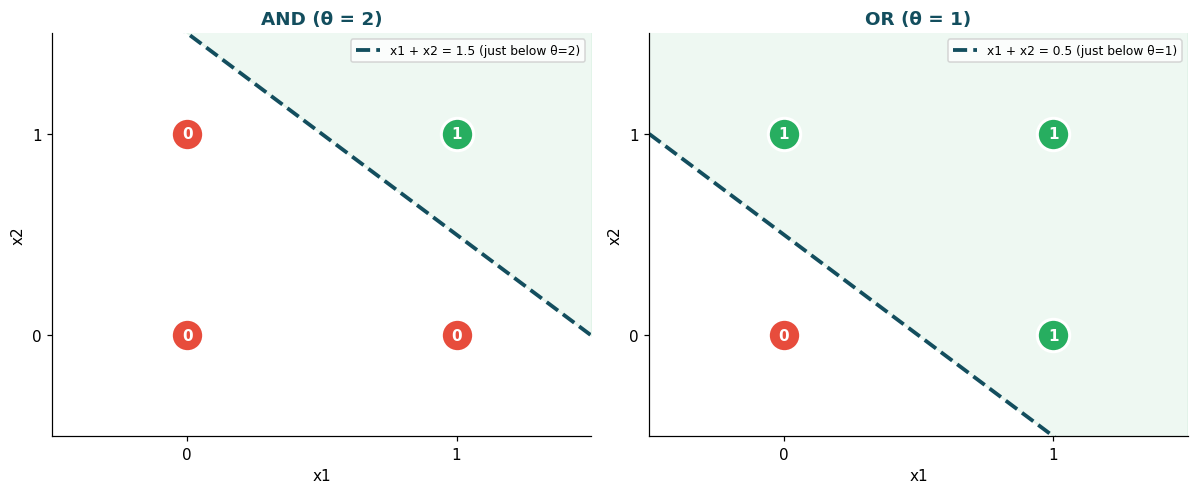

In [7]:
# Plot AND and OR as points + the straight line the neuron uses to separate them
def plot_gate(ax, func, theta, name):
    for a, b in itertools.product([0, 1], repeat=2):
        out = func(a, b)
        ax.scatter(a, b, s=450, color=GREEN if out else RED, edgecolor="white", linewidth=2, zorder=3)
        ax.text(a, b, str(out), ha="center", va="center", color="white", fontweight="bold", zorder=4)
    xs = np.linspace(-0.5, 1.5, 50)
    ax.plot(xs, (theta - 0.5) - xs, color=TEAL, lw=2.5, ls="--", label=f"x1 + x2 = {theta - 0.5} (just below θ={theta})")
    ax.fill_between(xs, (theta - 0.5) - xs, 2, color=GREEN, alpha=0.08)
    ax.set_xlim(-0.5, 1.5); ax.set_ylim(-0.5, 1.5)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xlabel("x1"); ax.set_ylabel("x2")
    ax.set_title(f"{name} (θ = {theta})", color=TEAL, fontweight="bold")
    ax.legend(loc="upper right", fontsize=8)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
plot_gate(axes[0], AND, 2, "AND")
plot_gate(axes[1], OR, 1, "OR")
plt.tight_layout()
plt.show()

## ❌ Step 8: The famous limit: XOR
> 💡 **XOR** means "one or the other, but **not both**": `0,0→0` · `0,1→1` · `1,0→1` · `1,1→0`.
>
> Can a single McCulloch-Pitts neuron do it? Let's **test every possible setup** by brute force:
> each input can be excitatory, inhibitory, or unused; we may add a constant `1`; and the threshold goes from 0 to 3.

In [8]:
# Try EVERY possible single-neuron setup with 2 inputs and see which truth tables are reachable
inputs_order = list(itertools.product([0, 1], repeat=2))   # (0,0) (0,1) (1,0) (1,1)
reachable = {}

for t1, t2 in itertools.product(["exc", "inh", "off"], repeat=2):
    for const in [0, 1]:
        for theta in range(0, 4):
            table = []
            for a, b in inputs_order:
                exc, inh = [], []
                for kind, value in [(t1, a), (t2, b)]:
                    if kind == "exc":
                        exc.append(value)
                    elif kind == "inh":
                        inh.append(value)
                if const:
                    exc.append(1)
                table.append(MPNeuron(theta)(exc, inh))
            reachable.setdefault(tuple(table), (t1, t2, const, theta))

XOR_TABLE = (0, 1, 1, 0)
print(f"Truth tables a single neuron can produce: {len(reachable)} out of 16 possible")
print("Can one neuron do XOR?  ->", XOR_TABLE in reachable)

Truth tables a single neuron can produce: 11 out of 16 possible
Can one neuron do XOR?  -> False


## 🔍 Step 9: Why can't it? (a picture)
> 💡 For XOR, the 🟢 points `(0,1)` and `(1,0)` sit on opposite corners, with 🔴 points on the other two.
> **No single straight line** can put both 🟢 on one side and both 🔴 on the other.
> But **two parallel lines** (a band in the middle) can! That hints that we need **two layers** of neurons.

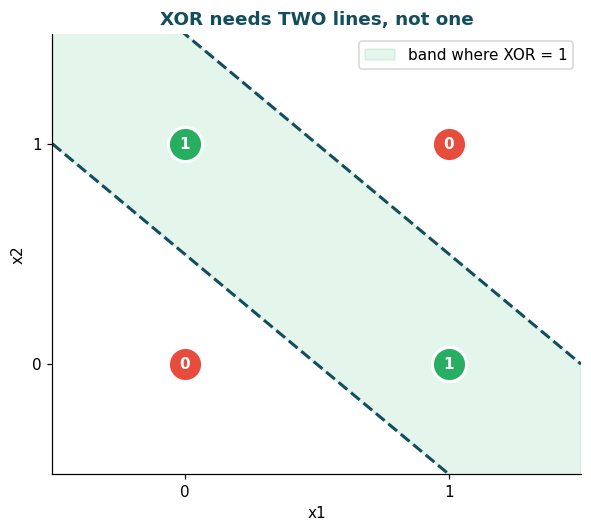

In [9]:
# Plot the XOR points and show why one line fails but a band (two lines) works
fig, ax = plt.subplots(figsize=(6.2, 5.2))
for a, b in itertools.product([0, 1], repeat=2):
    out = a ^ b
    ax.scatter(a, b, s=500, color=GREEN if out else RED, edgecolor="white", linewidth=2, zorder=3)
    ax.text(a, b, str(out), ha="center", va="center", color="white", fontweight="bold", zorder=4)

xs = np.linspace(-0.5, 1.5, 50)
ax.plot(xs, 0.5 - xs, color=TEAL, ls="--", lw=2)
ax.plot(xs, 1.5 - xs, color=TEAL, ls="--", lw=2)
ax.fill_between(xs, 0.5 - xs, 1.5 - xs, color=GREEN, alpha=0.12, label="band where XOR = 1")

ax.set_xlim(-0.5, 1.5); ax.set_ylim(-0.5, 1.5)
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xlabel("x1"); ax.set_ylabel("x2")
ax.set_title("XOR needs TWO lines, not one", color=TEAL, fontweight="bold")
ax.legend(loc="upper right")
plt.show()

## ✅ Step 10: Solving XOR with a tiny network
> 💡 The trick: **XOR = (x1 AND NOT x2) OR (x2 AND NOT x1)**
>
> ```
>  x1 ──(+)──► [ N1: θ=1 ] ──┐
>  x2 ──(−)──►               ├──► [ N3: OR, θ=1 ] ──► XOR
>  x2 ──(+)──► [ N2: θ=1 ] ──┘
>  x1 ──(−)──►
> ```
> (+) means excitatory and (−) means inhibitory. N1 fires when `x1=1` and `x2=0`. N2 fires when `x2=1` and `x1=0`. N3 fires if either of them fired.
> A network with **two layers** solves what one neuron cannot.

In [10]:
# Build XOR from three McCulloch-Pitts neurons arranged in two layers
def XOR(a, b):
    n1 = MPNeuron(1)([a], [b])       # fires when a = 1 and b = 0
    n2 = MPNeuron(1)([b], [a])       # fires when b = 1 and a = 0
    return MPNeuron(1)([n1, n2])     # OR of the two hidden neurons

xor_table = pd.DataFrame([{"x1": a, "x2": b, "XOR": XOR(a, b)} for a, b in itertools.product([0, 1], repeat=2)])
assert xor_table["XOR"].tolist() == [0, 1, 1, 0]
print("✅ XOR solved with a 2-layer network of MP neurons!")
xor_table

✅ XOR solved with a 2-layer network of MP neurons!


,x1,x2,XOR
0,0,0,0
1,0,1,1
2,1,0,1
3,1,1,0


## 🏠 Step 11: A real-life example: burglar alarm
> 💡 The alarm should ring if **the door OR the window** sensor is triggered, **unless the system is disarmed**.
> This is exactly one McCulloch-Pitts neuron: excitatory inputs = door, window (θ = 1), inhibitory input = disarmed.

In [11]:
# Burglar alarm = one neuron: (door OR window) AND NOT disarmed
alarm_neuron = MPNeuron(threshold=1)

alarm_rows = []
for door, window, disarmed in itertools.product([0, 1], repeat=3):
    ring = alarm_neuron([door, window], [disarmed])
    alarm_rows.append({"door open": door, "window open": window, "disarmed": disarmed,
                       "alarm rings": ring})
alarm_table = pd.DataFrame(alarm_rows)

def colour_alarm(row):
    c = "background-color:#fdebd0" if row["alarm rings"] == 1 else "background-color:#eaf2f8"
    return [c] * len(row)

alarm_table.style.apply(colour_alarm, axis=1)

,door open,window open,disarmed,alarm rings
0,0,0,0,0
1,0,0,1,0
2,0,1,0,1
3,0,1,1,0
4,1,0,0,1
5,1,0,1,0
6,1,1,0,1
7,1,1,1,0


## ➕ Step 12: Computers can add with neurons
> 💡 A **half adder** adds two single bits. It gives:
> - **Sum bit** = XOR of the inputs
> - **Carry bit** = AND of the inputs
>
> So `1 + 1 = 10` in binary (carry = 1, sum = 0). We build it only from our neurons.

In [12]:
# Half adder built from McCulloch-Pitts neurons
def half_adder(a, b):
    return XOR(a, b), AND(a, b)      # (sum bit, carry bit)

adder_rows = []
for a, b in itertools.product([0, 1], repeat=2):
    s, c = half_adder(a, b)
    adder_rows.append({"a": a, "b": b, "carry": c, "sum": s,
                       "binary result": f"{c}{s}", "decimal": a + b})
    assert 2 * c + s == a + b          # check the maths!
print("✅ The adder is correct!")
pd.DataFrame(adder_rows)

✅ The adder is correct!


,a,b,carry,sum,binary result,decimal
0,0,0,0,0,00,0
1,0,1,0,1,01,1
2,1,0,0,1,01,1
3,1,1,1,0,10,2


## 🧮 Step 13: How many things can a neuron compute?
> 💡 With `n` binary inputs there are `2^(2^n)` possible truth tables.

In [13]:
# Count all possible Boolean functions for different numbers of inputs
counts = pd.DataFrame({"inputs (n)": [1, 2, 3, 4, 5]})
counts["input combinations (2^n)"] = 2 ** counts["inputs (n)"]
counts["possible functions (2^(2^n))"] = 2 ** counts["input combinations (2^n)"]
counts

,inputs (n),input combinations (2^n),possible functions (2^(2^n))
0,1,2,4
1,2,4,16
2,3,8,256
3,4,16,65536
4,5,32,4294967296


## ⚠️ Limitations of the McCulloch-Pitts neuron

| Limitation | What it means | Who fixed it |
|---|---|---|
| ❌ **No learning** | Thresholds must be chosen by a human | Hebb's rule (1949), Perceptron (1958) |
| ❌ **Binary only** | Inputs and outputs are only 0 or 1 | Real-valued inputs in later models |
| ❌ **All inputs count the same** | No weights, so no input can matter more than another | Weighted sums (Perceptron) |
| ❌ **One neuron can't do XOR** | Only linearly separable problems | Multi-layer networks + Backpropagation (1986) |

### 🧬 What it gave us
- The idea that **a neuron = weighted-sum-and-threshold**, which still lives inside every neural network today
- Proof that **simple units + connections = computation**

## 📝 Summary
1. ✅ The McCulloch-Pitts neuron (1943) sums binary inputs and fires if the sum reaches θ.
2. ✅ Inhibitory inputs can block it completely.
3. ✅ One neuron can act as AND, OR, NOT and NOR.
4. ✅ One neuron **cannot** do XOR, but a small two-layer network can.
5. ✅ Networks of these neurons can build adders, alarms and more.

## 🧪 Practice time
**Exercise 1.** Build a neuron that fires when **at least 3 of 4** inputs are on.

**Exercise 2.** Build a neuron for: *"Go out for ice cream if it is sunny OR it is hot, but NOT if you have homework."*

**Exercise 3.** Show with the brute-force method from Step 8 that **XNOR** (`1,0,0,1`) also cannot be done by one neuron.

<details>
<summary>👀 Click to see the solutions</summary>

```python
# Exercise 1: at least 3 of 4
at_least_3 = MPNeuron(threshold=3)
print(at_least_3([1, 1, 1, 0]), at_least_3([1, 1, 0, 0]))   # 1 0

# Exercise 2: (sunny OR hot) AND NOT homework
ice_cream = MPNeuron(threshold=1)
print(ice_cream([1, 0], [0]), ice_cream([1, 1], [1]))        # 1 0

# Exercise 3: XNOR in reachable ?
print((1, 0, 0, 1) in reachable)                             # False
```
</details>

## ⏭️ Next notebook
**02: The Perceptron (1958)**: the first neuron that **learns its own weights from data**. 🚀